# Step 3: EDA charts

Charts for the rating factors, claim severity, cost concentration and correlations, drawn from the clean layer (`policies_clean`, `claims_clean`). The segment numbers match `sql/04_eda.sql`. Charts are also saved to `figures/` for the README.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, PercentFormatter
from dotenv import load_dotenv
from sqlalchemy import create_engine, URL

load_dotenv(".env", override=True)

url = URL.create(
    "mysql+pymysql",
    username=os.environ["DB_USER"],
    password=os.environ["DB_PASSWORD"],
    host=os.environ["DB_HOST"],
    port=int(os.environ["DB_PORT"]),
    database=os.environ["DB_NAME"],
)
engine = create_engine(url)

# Chart style: one blue for the data, gray hairlines for everything else
BLUE, RED = "#2a78d6", "#e34948"
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, NEUTRAL = "#e1e0d9", "#c3c2b7", "#f0efec"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left",
})
os.makedirs("figures", exist_ok=True)


def compact(v, _=None):
    # 1,000 -> 1K, 1,000,000 -> 1M for axis ticks
    for div, suffix in ((1e6, "M"), (1e3, "K")):
        if abs(v) >= div:
            return f"{v / div:g}{suffix}"
    return f"{v:g}"

In [2]:
policies = pd.read_sql("SELECT * FROM policies_clean", engine)
claims = pd.read_sql("SELECT * FROM claims_clean", engine)

# DECIMAL columns arrive as Python Decimals; convert to floats
policies[["exposure", "claim_amount_total"]] = policies[["exposure", "claim_amount_total"]].astype(float)
claims["claim_amount"] = claims["claim_amount"].astype(float)

print(f"policies: {len(policies):,}  claims: {len(claims):,}")

policies: 678,013  claims: 26,444


In [3]:
# Same bands as sql/04_eda.sql (each band includes its upper edge)
policies["driv_age_band"] = pd.cut(policies.driv_age, [17, 20, 25, 35, 50, 65, np.inf],
                                   labels=["18-20", "21-25", "26-35", "36-50", "51-65", "66+"])
policies["bm_band"] = pd.cut(policies.bonus_malus, [49, 50, 75, 100, 125, np.inf],
                             labels=["50", "51-75", "76-100", "101-125", "126+"])
policies["veh_age_band"] = pd.cut(policies.veh_age, [-1, 0, 4, 10, 20, np.inf],
                                  labels=["0", "1-4", "5-10", "11-20", "21+"])
policies["density_band"] = pd.cut(policies.density, [0, 49, 199, 499, 1999, 9999, np.inf],
                                  labels=["<50", "50-199", "200-499", "500-1999", "2000-9999", "10000+"])


def segment(col):
    # exposure-weighted frequency, severity and pure premium per level of col
    g = policies.groupby(col, observed=True).agg(
        exposure=("exposure", "sum"), claims=("claim_nb", "sum"), cost=("claim_amount_total", "sum"))
    g["frequency"] = g.claims / g.exposure
    g["severity"] = g.cost / g.claims.replace(0, np.nan)
    g["pure_premium"] = g.cost / g.exposure
    return g


PORTFOLIO_FREQ = policies.claim_nb.sum() / policies.exposure.sum()

# Cross-check against sql/04_eda.sql, so the charts and the README tables agree
assert round(PORTFOLIO_FREQ, 4) == 0.0737
assert round(segment("bm_band").loc["50", "frequency"], 4) == 0.0513
assert round(segment("density_band").loc["10000+", "exposure"]) == 8125
print(f"portfolio frequency {PORTFOLIO_FREQ:.4f}: matches sql/04_eda.sql")

portfolio frequency 0.0737: matches sql/04_eda.sql


## 1. Claim frequency by rating factor

Top panel: claims per policy-year, with the portfolio average as a line. Bottom panel: exposure in each group, so thin groups are easy to spot. They are two panels rather than one chart with two y-axes, because two scales on one chart make the series look related when they aren't.

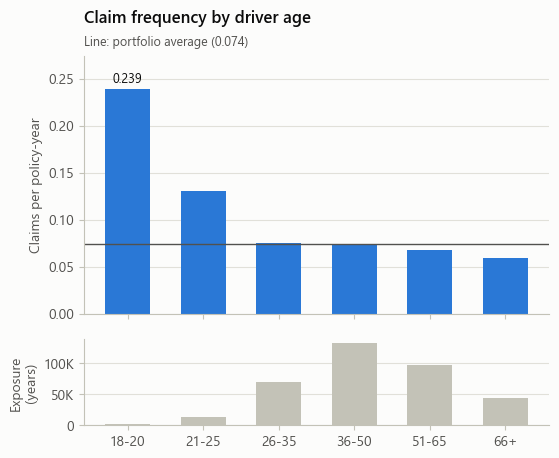

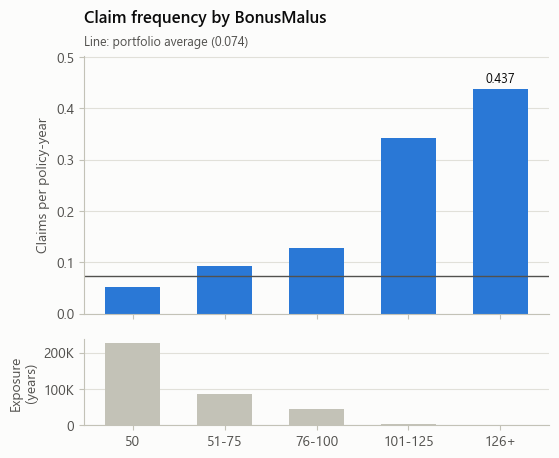

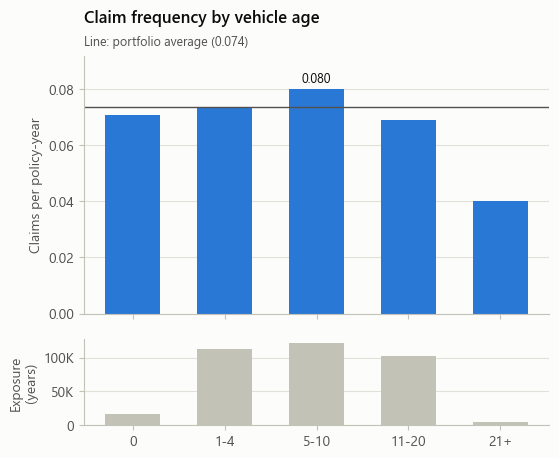

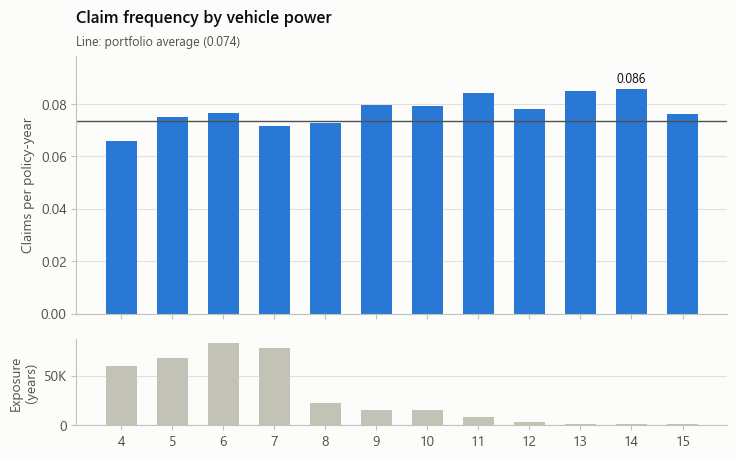

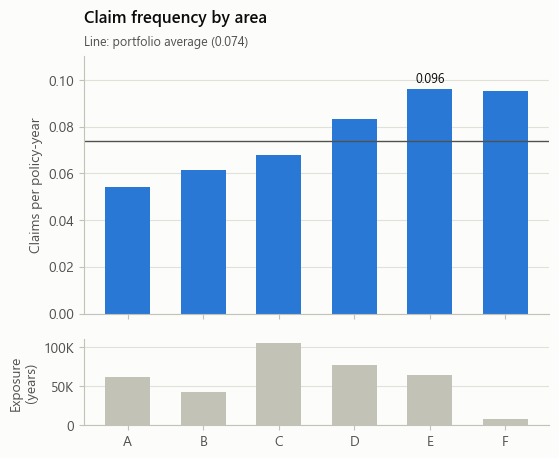

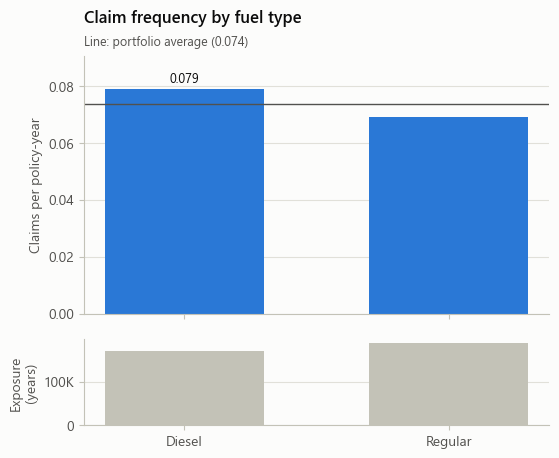

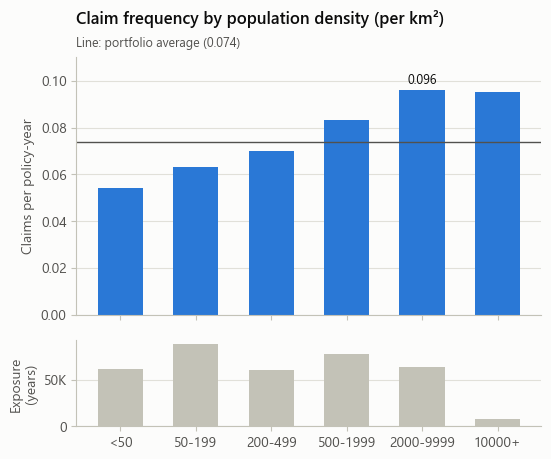

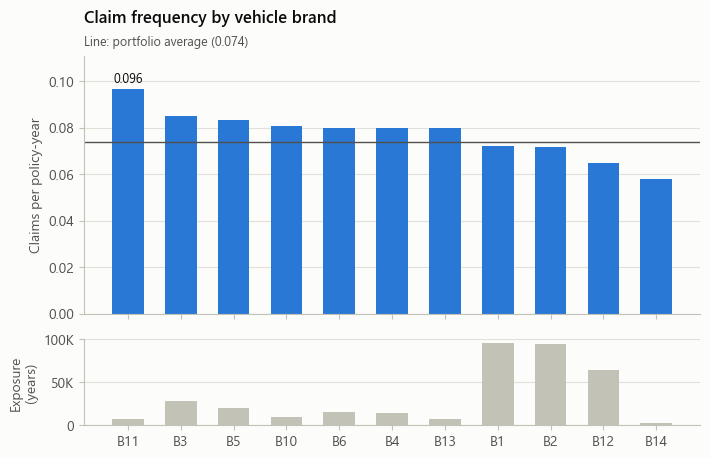

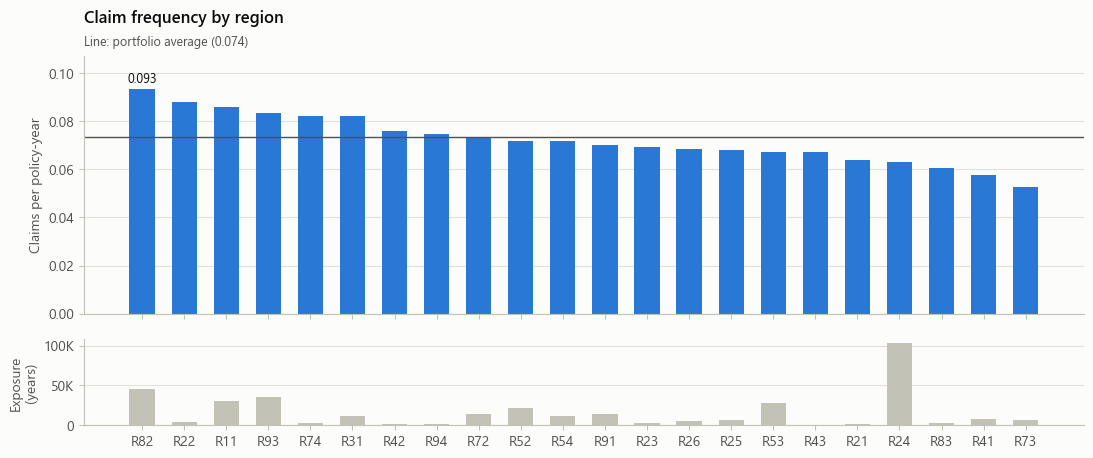

In [4]:
def plot_factor(col, title, sort_by_freq=False):
    seg = segment(col)
    if sort_by_freq:
        seg = seg.sort_values("frequency", ascending=False)
    x = np.arange(len(seg))

    fig, (ax_f, ax_e) = plt.subplots(
        2, 1, figsize=(max(6, 0.45 * len(seg) + 3), 4.8), sharex=True,
        gridspec_kw={"height_ratios": [3, 1], "hspace": 0.15})

    ax_f.bar(x, seg.frequency, width=0.6, color=BLUE)
    ax_f.axhline(PORTFOLIO_FREQ, color=INK_2, linewidth=1)
    top = int(seg.frequency.values.argmax())
    ax_f.annotate(f"{seg.frequency.iloc[top]:.3f}", (x[top], seg.frequency.iloc[top]),
                  xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9)
    ax_f.set_ylim(0, seg.frequency.max() * 1.15)
    ax_f.set_ylabel("Claims per policy-year")
    ax_f.set_title(title, pad=24)
    ax_f.text(0, 1.04, f"Line: portfolio average ({PORTFOLIO_FREQ:.3f})",
              transform=ax_f.transAxes, color=INK_2, fontsize=9)

    ax_e.bar(x, seg.exposure, width=0.6, color=AXIS)
    ax_e.yaxis.set_major_formatter(FuncFormatter(compact))
    ax_e.set_ylabel("Exposure\n(years)")
    ax_e.set_xticks(x, seg.index.astype(str))

    fig.savefig(f"figures/freq_{col}.png", dpi=150, bbox_inches="tight")
    plt.show()


factors = [
    ("driv_age_band", "Claim frequency by driver age", False),
    ("bm_band", "Claim frequency by BonusMalus", False),
    ("veh_age_band", "Claim frequency by vehicle age", False),
    ("veh_power", "Claim frequency by vehicle power", False),
    ("area", "Claim frequency by area", False),
    ("veh_gas", "Claim frequency by fuel type", False),
    ("density_band", "Claim frequency by population density (per km²)", False),
    ("veh_brand", "Claim frequency by vehicle brand", True),
    ("region", "Claim frequency by region", True),
]
for col, title, sort_by_freq in factors:
    plot_factor(col, title, sort_by_freq)

## 2. Claim severity distribution

Log x-axis, because claim amounts run from 1 to over 4 million. The 99.5th percentile is the large-claim cap planned for Step 4.

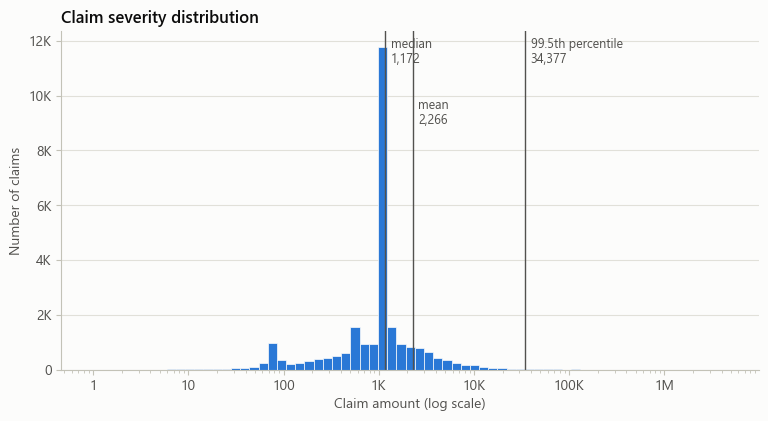

count      26444.00
mean        2265.51
std        29371.03
min            1.00
25%          685.99
50%         1172.00
75%         1212.38
90%         2767.60
99%        16451.22
99.5%      34376.96
max      4075400.56
share of claims between 1,000 and 1,300: 45.7%


In [5]:
amounts = claims.claim_amount
markers = [("median", amounts.median()), ("mean", amounts.mean()), ("99.5th percentile", amounts.quantile(0.995))]

fig, ax = plt.subplots(figsize=(9, 4.4))
bins = np.logspace(0, np.log10(amounts.max()) + 0.05, 70)
ax.hist(amounts, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(compact))
ax.yaxis.set_major_formatter(FuncFormatter(compact))
for (name, value), y in zip(markers, (0.98, 0.80, 0.98)):
    ax.axvline(value, color=INK_2, linewidth=1)
    ax.annotate(f"{name}\n{value:,.0f}", (value, y), xycoords=("data", "axes fraction"),
                xytext=(4, 0), textcoords="offset points", ha="left", va="top", fontsize=9, color=INK_2)
ax.set_xlabel("Claim amount (log scale)")
ax.set_ylabel("Number of claims")
ax.set_title("Claim severity distribution")
fig.savefig("figures/severity_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print(amounts.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99, 0.995]).round(2).to_string())
print(f"share of claims between 1,000 and 1,300: {amounts.between(1000, 1300).mean():.1%}")

## 3. Concentration of claim cost

Claims sorted from largest to smallest. The curve shows what share of total claim cost comes from the largest x% of claims; the diagonal is what it would look like if every claim cost the same.

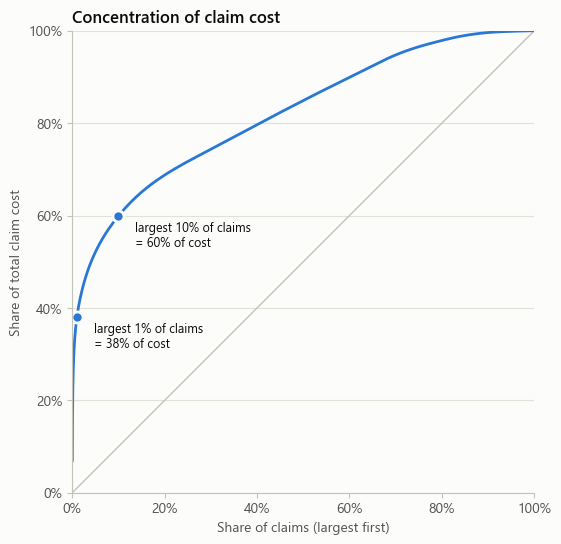

In [6]:
sorted_amounts = np.sort(amounts.values)[::-1]
claim_share = np.arange(1, len(sorted_amounts) + 1) / len(sorted_amounts)
cost_share = sorted_amounts.cumsum() / sorted_amounts.sum()

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], color=AXIS, linewidth=1)
ax.plot(claim_share, cost_share, color=BLUE, linewidth=2, solid_capstyle="round")
for p in (0.01, 0.10):
    i = int(np.ceil(p * len(sorted_amounts))) - 1  # same 265 claims as NTILE(100) in sql/04_eda.sql
    ax.plot(claim_share[i], cost_share[i], "o", color=BLUE, markersize=8,
            markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f"largest {p:.0%} of claims\n= {cost_share[i]:.0%} of cost", (claim_share[i], cost_share[i]),
                xytext=(12, -4), textcoords="offset points", va="top", fontsize=9)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Share of claims (largest first)")
ax.set_ylabel("Share of total claim cost")
ax.set_title("Concentration of claim cost")
fig.savefig("figures/cost_concentration.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Correlation between numeric rating factors

Spearman (rank) correlation, because density and BonusMalus are very skewed. Strongly related factors carry overlapping information, which matters for reading GLM coefficients later.

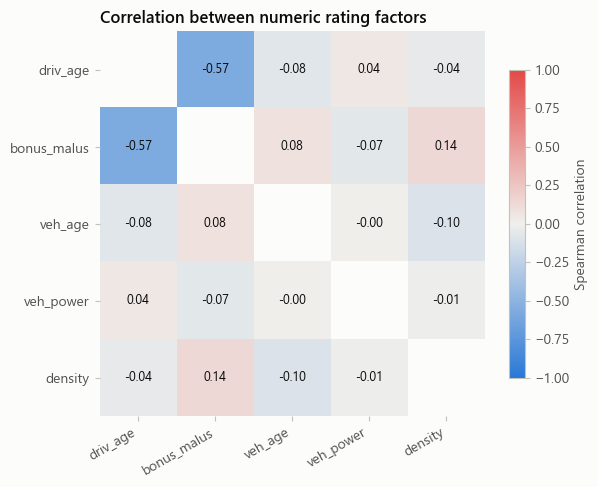

In [7]:
num_cols = ["driv_age", "bonus_malus", "veh_age", "veh_power", "density"]
corr = policies[num_cols].corr(method="spearman")

cmap = LinearSegmentedColormap.from_list("blue_gray_red", [BLUE, NEUTRAL, RED])
fig, ax = plt.subplots(figsize=(6.4, 5))
shown = corr.mask(np.eye(len(num_cols), dtype=bool))  # hide the diagonal, which is always 1
im = ax.imshow(shown, cmap=cmap, vmin=-1, vmax=1)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks(range(len(num_cols)), num_cols, rotation=30, ha="right")
ax.set_yticks(range(len(num_cols)), num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        if i == j:
            continue
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="#ffffff" if abs(v) > 0.6 else INK)
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman correlation")
ax.set_title("Correlation between numeric rating factors")
fig.savefig("figures/correlation.png", dpi=150, bbox_inches="tight")
plt.show()

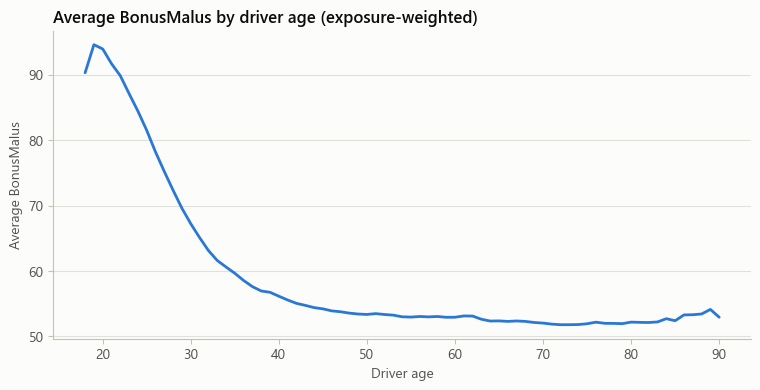

driv_age
18    90.3
20    94.0
25    81.5
30    67.2
40    56.1
50    53.3
60    52.9
70    52.0


In [8]:
# BonusMalus vs driver age in detail: exposure-weighted average BonusMalus at each age
by_age = (policies.assign(bm_x_exposure=policies.bonus_malus * policies.exposure)
          .groupby("driv_age")[["bm_x_exposure", "exposure"]].sum())
by_age = by_age[by_age.exposure >= 100]  # drop ages with too little exposure to be stable
avg_bm = by_age.bm_x_exposure / by_age.exposure

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(avg_bm.index, avg_bm.values, color=BLUE, linewidth=2, solid_capstyle="round")
ax.set_xlabel("Driver age")
ax.set_ylabel("Average BonusMalus")
ax.set_title("Average BonusMalus by driver age (exposure-weighted)")
fig.savefig("figures/bonus_malus_by_age.png", dpi=150, bbox_inches="tight")
plt.show()

print(avg_bm.loc[[18, 20, 25, 30, 40, 50, 60, 70]].round(1).to_string())